# Drag Pulse Calibration

In [1]:
from pathlib import Path

import numpy as np

from qblox_lab.config.device import save_device_configuration
from qblox_lab.config.hardware import create_hardware_agent
from qblox_lab.config.sessions import CONFIG_DIR, SESSIONS
from qblox_lab.config.session_paths import save_config_snapshot, save_result_figures
from qblox_lab.experiments.cal18a_RB import MultiplexedSingleQubitRB

Generating hash table for SingleQubitClifford.
Hash table generated.
Generating hash table for TwoQubitCliffordCZ.
Hash table generated.
Generating hash table for TwoQubitCliffordZX.
Hash table generated.


## Run parameters

In [2]:
SESSION = SESSIONS["AS_QRC"]
HARDWARE_CONFIG = SESSION.hardware_config
DEVICE_CONFIG = SESSION.device_config
FLUX_CONFIG = SESSION.flux_config  # If None, leave the existing hardware flux unchanged
OUTPUT_DIR = SESSION.output_dir
EXPERIMENT_NAME = "single_qubit_RB"

QUBITS = ["q1"]
CLIFFORD_LENGTHS = [1, 2, 10, 20, 40, 60, 80, 100]
N_SEEDS = 10
REPETITIONS = 1000
RESET_TYPE = "thermal"  # "thermal" or "active" (ConditionalReset)

TIMEOUT = 300
CREATE_DUMMY_CONNECTIONS = False

PLOT_RESULTS = True
SAVE_FITTED_DEVICE = SESSION.device_config

## Hardware and experiment

In [3]:
import atexit

from qcodes.instrument import Instrument

hardware_agent = create_hardware_agent(
    hardware_configuration=HARDWARE_CONFIG,
    device_configuration=DEVICE_CONFIG,
    output_dir=OUTPUT_DIR,
    create_dummy_connections=CREATE_DUMMY_CONNECTIONS,
)

experiment = MultiplexedSingleQubitRB(
    hardware_agent=hardware_agent,
    qubits=QUBITS,
    flux_config=FLUX_CONFIG,
)

atexit.register(Instrument.close_all)

<bound method Instrument.close_all of <class 'qcodes.instrument.instrument.Instrument'>>

## Measurement

In [4]:
dataset = experiment.run_measurement(
    repetitions=REPETITIONS,
    reset_type=RESET_TYPE,
    clifford_lengths=CLIFFORD_LENGTHS,
    n_seeds=N_SEEDS,
    timeout=TIMEOUT,
)
dataset

<xarray.Dataset> Size: 3kB
Dimensions:            (acq_index_S_21_q1: 80)
Coordinates:
  * acq_index_S_21_q1  (acq_index_S_21_q1) int64 640B 0 1 2 3 4 ... 76 77 78 79
    m_q1               (acq_index_S_21_q1) int64 640B 1 1 1 1 ... 100 100 100
    seed_q1            (acq_index_S_21_q1) int64 640B 0 1 2 3 4 5 ... 5 6 7 8 9
Data variables:
    S_21_q1            (acq_index_S_21_q1) float64 640B 0.28 0.308 ... 0.513
Attributes:
    tuid:     20261016-115922-941-c0fde5

## Optional: Simulated data

In [5]:
# dataset = experiment.simulated_data(
#     delays=DELAYS,
#     repetitions=REPETITIONS,
#     t1=100e-6,
#     noise=0.002,
#     seed=42,
# )

## Analysis

In [6]:
results = experiment.analysis()


Running Thresholded RB Analysis for q1...
[q1] Fit Success! p = 0.97246
[q1] Error Per Clifford (EPC) = 1.3770%


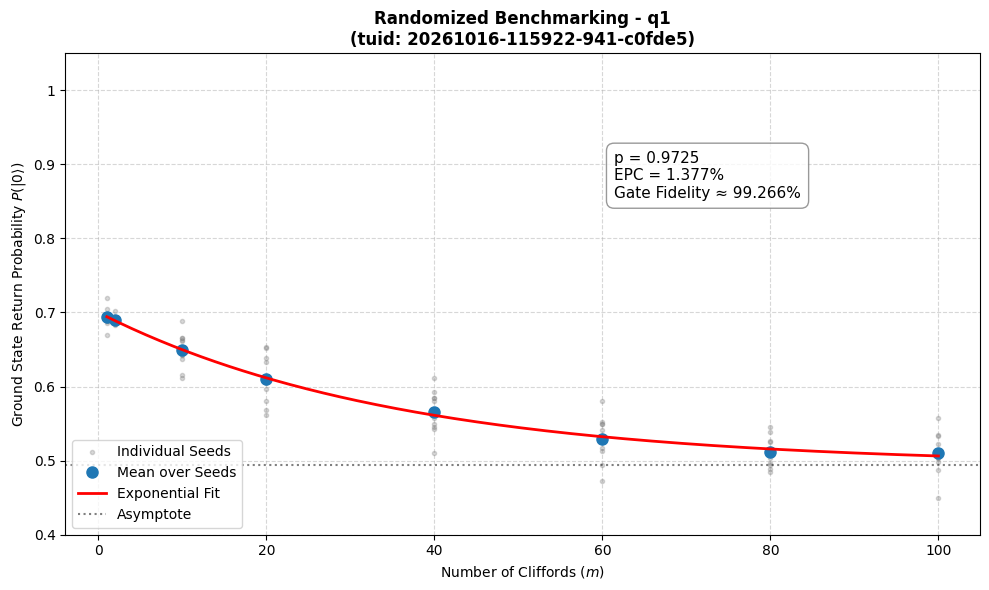

In [7]:
if PLOT_RESULTS:
    experiment.plot_analysis()

In [8]:
if PLOT_RESULTS and experiment.figures:
    save_result_figures(SESSION, dataset, EXPERIMENT_NAME, experiment.figures)
save_config_snapshot(SESSION, dataset, EXPERIMENT_NAME)


## Release hardware connection

In [ ]:
from qcodes.instrument import Instrument

Instrument.close_all()